# ISP Field Operations — Data Analyst Take-Home Assessment

## Overview
You've been given 6 weeks of ticket data ("CRQ" — Change Request / work-order tickets) from an
ISP's field operations team, covering installations, repairs, and relocations. Your job is to turn
this into a financial and operational performance story that an operations lead could act on.

## Files provided
- `tickets.xlsx` — raw ticket-level data (sheet: **Tickets**)
- `business_assumptions.json` — pricing, salary, and SLA assumptions you **must** use

## Ground rules
1. Load `business_assumptions.json` **programmatically** — never hardcode `price_per_ticket`,
   `engineer_monthly_salary`, or `sla_target_hours` directly in a formula. We want to see you read
   config, not memorize it.
2. Revenue is recognized **only** when a ticket's `status` is `"Closed"`. Open tickets are
   unbilled / at-risk revenue, not confirmed revenue.
3. Derive week boundaries yourself from `created_date` (Monday-start weeks). We deliberately did
   **not** pre-compute a week column — that's part of the exercise.
4. **Prefer visualizations over printed tables.** A wall of numbers is not an insight — a clearly
   labeled chart is. Use matplotlib (or any plotting library you like); keep charts simple, titled,
   and labeled.
5. Keep code readable: small steps, meaningful variable names, comments where the "why" isn't
   obvious.
6. Handle missing data explicitly — open tickets have null `resolution_hours` / `closed_date`.
   Don't let this silently break (or silently corrupt) your numbers.
7. Where a question is ambiguous, state your assumption in one short markdown line and move on
   (e.g. how you prorate a monthly salary into a weekly figure).

## What we're evaluating
- Correctness of the financial and operational logic
- Data handling (nulls, dtypes, edge cases like a ticket that's still open)
- Quality and clarity of visualizations (does the chart make the point on its own?)
- Business judgement in the written interpretation sections
- Code organization and readability
- **Bonus:** anything insightful you found that we didn't explicitly ask for

Answer every question in its own cell(s), in order, using the section headers to organize your
notebook. Good luck.


## Table of Contents

- [Section A — Setup & Data Quality](#section-a)
  - [A1. Load data & assumptions](#a1)
  - [A2. Data-quality summary](#a2)
  - [A3. Derive week_start](#a3)
- [Section B — Revenue, Expenses & Profit](#section-b)
  - [B1. Weekly revenue](#b1)
  - [B2. At-risk revenue](#b2)
  - [B3. Weekly expenses](#b3)
  - [B4. Weekly profit](#b4)
  - [B5. Week-over-week % change](#b5)
  - [B6. Cumulative profit](#b6)
  - [B7. Revenue projection](#b7)
- [Section C — SLA & MTTR](#section-c)
  - [C1. Overall MTTR](#c1)
  - [C2. Weekly MTTR trend](#c2)
  - [C3. SLA compliance](#c3)
  - [C4. Resolution time distribution & outliers](#c4)
  - [C5. Backlog trend](#c5)
- [Section D — Engineer Performance & Profitability](#section-d)
  - [D1. Ticket volume per engineer](#d1)
  - [D2. Net contribution per engineer](#d2)
  - [D3. Net positive/negative engineers](#d3)
  - [D4. SLA compliance vs. volume](#d4)
  - [D5. Staffing recommendation (written)](#d5)
- [Section E — Recurrence / Account Analysis](#section-e)
  - [E1. Recurring accounts](#e1)
  - [E2. Top 10 accounts](#e2)
  - [E3. Written interpretation](#e3)
- [Section F — Regional View (bonus depth)](#section-f)
  - [F1. Regional comparison](#f1)
  - [F2. Written recommendation](#f2)
- [Section G — Synthesis](#section-g)
  - [G1. Headline synthesis](#g1)
- [Bonus Section](#bonus-section)
  - [Investigation of Recurring Accounts by Region & Issue Type](#bonus-recurring)
  - [Engineer Risk Matrix](#bonus-risk-matrix)
  - [Engineer x Region Heatmap Distribution](#bonus-heatmap)

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from scipy.stats import gaussian_kde

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
sns.set_theme(style="whitegrid")

DATA_DIR = "./data"  # tickets.xlsx and business_assumptions.json sit in a folder named data in the root folder


<a id="section-a"></a>
### Section A — Setup & Data Quality

<a id="a1"></a>
**A1.** Load `tickets.xlsx` (sheet `Tickets`) and `business_assumptions.json`. Parse all date columns properly, and pull the assumption values into named variables.

In [4]:
# load the .xlsx dataset
tickets = pd.read_excel(f"{DATA_DIR}/tickets.xlsx", sheet_name="Tickets")

# date column parsing and conversion of date column variables into datetime objects
tickets["created_date"] = pd.to_datetime(tickets["created_date"])
tickets["closed_date"] = pd.to_datetime(tickets["closed_date"])

# Load the business assumptions json
with open(f"{DATA_DIR}/business_assumptions.json") as p:
    assumptions = json.load(p)

# load business assumptions into named variables
currency = assumptions['currency']
price_per_ticket = assumptions['price_per_ticket']
engineer_monthly_salary = assumptions['engineer_monthly_salary']
weeks_per_month = assumptions['weeks_per_month']
sla_target_hours = assumptions['sla_target_hours']

# Prorated weekly salary cost per engineer - Global variable to be used in later calculations
engineer_weekly_salary = engineer_monthly_salary / weeks_per_month

# print the named variables
print(f"Loaded: {len(tickets):,} tickets")
print(f"Currency: {currency}")
print(f"Price per ticket: {price_per_ticket:,}")
print(f"Engineer weekly salary (prorated): {engineer_weekly_salary:,.2f}")
print(f"SLA target: {sla_target_hours} hours")

Loaded: 246 tickets
Currency: KES
Price per ticket: 5,000
Engineer weekly salary (prorated): 6,928.41
SLA target: 24 hours


**The prorated engineer weekly salary is obtained by dividing up the engineer monthly salary by the number of weeks per month as defined in the business assumptions.**

<a id="a2"></a>
**A2.** Produce a short data-quality summary: row count, columns, null counts per column, and the open-vs-closed ticket split.

In [5]:
print("=== Shape ===")
print(f"Rows: {tickets.shape[0]:,}  |  Columns: {tickets.shape[1]}")

print("\n=== Columns & dtypes ===")
print(tickets.dtypes)

print("\n=== Null counts per column ===")
null_counts = tickets.isnull().sum()
print(null_counts[null_counts > 0])  # only show columns that actually have nulls

print("\n=== Open vs Closed split ===")
status_counts = tickets["status"].value_counts()
status_pct = tickets["status"].value_counts(normalize=True).mul(100).round(1)
status_summary = pd.DataFrame({"count": status_counts, "pct(%)": status_pct})
print(status_summary)

=== Shape ===
Rows: 246  |  Columns: 9

=== Columns & dtypes ===
ticket_number                  str
account_number                 str
engineer                       str
region                         str
issue_type                     str
created_date        datetime64[us]
status                         str
closed_date         datetime64[us]
resolution_hours           float64
dtype: object

=== Null counts per column ===
closed_date         52
resolution_hours    52
dtype: int64

=== Open vs Closed split ===
        count  pct(%)
status               
Closed    194    78.9
Open       52    21.1


In [6]:
# Sanity check: nulls in closed_date/resolution_hours should exactly match open tickets
open_mask = tickets["status"] != "Closed"
assert (tickets["closed_date"].isnull() == open_mask).all(), "Mismatch between open tickets and null closed_date"
assert (tickets["resolution_hours"].isnull() == open_mask).all(), "Mismatch between open tickets and null resolution_hours"
print(f"\n✓ Confirmed: {open_mask.sum()} open tickets, all with null closed_date/resolution_hours as expected")


✓ Confirmed: 52 open tickets, all with null closed_date/resolution_hours as expected


<a id="a3"></a>
**A3.** Derive a `week_start` (Monday) for every ticket from `created_date`. Print the resulting week ranges present in the data.

In [7]:
# Derive week_start (Monday) from created_date
# Normalize to midnight first (drops the time-of-day component), then snap back
# to the Monday of that week. Pandas weekday: Monday=0 ... Sunday=6.
tickets["week_start"] = (
    tickets["created_date"].dt.normalize()
    - pd.to_timedelta(tickets["created_date"].dt.weekday, unit="D")
)

# Sanity check: every week_start should actually be a Monday
assert (tickets["week_start"].dt.weekday == 0).all(), "Non-Monday week_start found"

week_ranges = tickets["week_start"].sort_values().unique()
print(f"{len(week_ranges)} distinct weeks in the dataset:\n")
for ws in week_ranges:
    we = pd.Timestamp(ws) + pd.Timedelta(days=6)
    print(f"  {pd.Timestamp(ws).date()}  →  {we.date()}")

6 distinct weeks in the dataset:

  2026-06-08  →  2026-06-14
  2026-06-15  →  2026-06-21
  2026-06-22  →  2026-06-28
  2026-06-29  →  2026-07-05
  2026-07-06  →  2026-07-12
  2026-07-13  →  2026-07-19


In [8]:
# First 5 columns of the dataset with the new added week_start column
tickets.head()

,ticket_number,account_number,engineer,region,issue_type,created_date,status,closed_date,resolution_hours,week_start
0,WOT100018,ACC30015,Grace Achieng,Rift Valley,Installation,2026-06-08 00:05:45.882,Closed,2026-06-09 08:47:45.882,32.7,2026-06-08
1,WOT100019,ACC30016,Grace Achieng,Rift Valley,Installation,2026-06-08 09:43:53.083,Closed,2026-06-09 06:25:53.083,20.7,2026-06-08
2,WOT100023,ACC30019,Sarah Njoroge,Nairobi,Installation,2026-06-08 10:45:22.798,Closed,2026-06-08 21:57:22.798,11.2,2026-06-08
3,WOT100020,ACC30017,Grace Achieng,Nairobi,Installation,2026-06-08 11:37:39.662,Closed,2026-06-09 06:55:39.662,19.3,2026-06-08
4,WOT100026,ACC20007,Dennis Kiptoo,Rift Valley,Installation,2026-06-08 16:17:03.660,Closed,2026-06-09 13:23:03.660,21.1,2026-06-08


Week_start is derived from created_date, not closed_date. A ticket created in week 3 but closed in week 5 is still attributed to week 3 for volume/backlog analysis — revenue, however, is only recognized once the ticket closes, so a given week's revenue can include tickets created in earlier weeks that closed that week.

<a id="section-b"></a>
### Section B — Revenue, Expenses & Profit

<a id="b1"></a>
**B1.** Compute total revenue accrued (closed tickets only) for the whole period, and by week. Plot weekly revenue as a bar chart.

Total recognized revenue: KES 970,000  (194 closed tickets)

Weekly revenue:
week_start  revenue
2026-06-08   135000
2026-06-15   170000
2026-06-22   180000
2026-06-29   190000
2026-07-06   150000
2026-07-13   145000


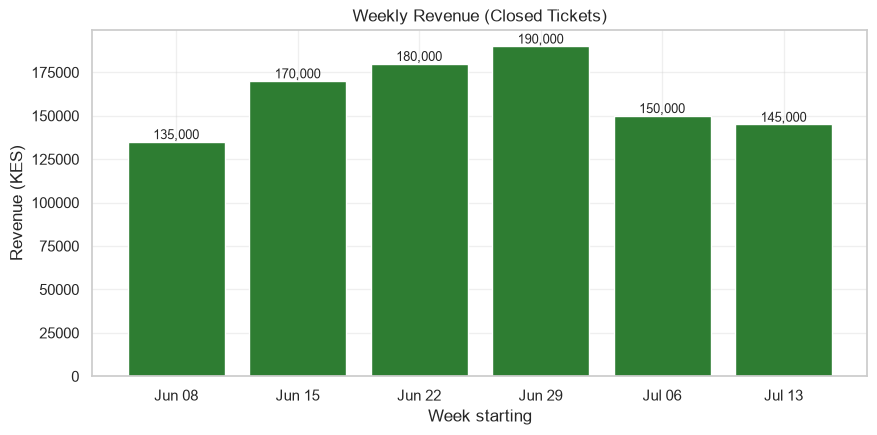

In [9]:
# create a copy dataset with only closed tickets data and add a revenue column
closed_tickets = tickets[tickets["status"] == "Closed"].copy()
closed_tickets["revenue"] = price_per_ticket  

# --- Total revenue for the whole period ---
total_revenue = closed_tickets["revenue"].sum()
print(f"Total recognized revenue: {currency} {total_revenue:,.0f}  ({len(closed_tickets)} closed tickets)")

# --- Weekly revenue ---
# Grouped by week_start and used to calculate cumulative sum for any given week.
weekly_revenue = (
    closed_tickets.groupby("week_start")["revenue"]
    .sum()
    .reset_index()
    .sort_values("week_start")
)

print("\nWeekly revenue:")
print(weekly_revenue.to_string(index=False))

# --- Plot ---
fig, ax = plt.subplots()
ax.bar(
    weekly_revenue["week_start"].dt.strftime("%b %d"),
    weekly_revenue["revenue"],
    color="#2E7D32",
)
ax.set_title("Weekly Revenue (Closed Tickets)")
ax.set_xlabel("Week starting")
ax.set_ylabel(f"Revenue ({currency})")
for i, v in enumerate(weekly_revenue["revenue"]):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
# plt.tight_layout()
plt.show()

<a id="b2"></a>
**B2.** Compute "missed / at-risk revenue" — the revenue represented by currently OPEN tickets. Show it alongside recognized revenue per week.

In [10]:
# create a copy dataset with only open tickets data and add a revenue column
open_tickets = tickets[tickets["status"] == "Open"].copy()
open_tickets ["at_risk_revenue"] = price_per_ticket  


# --- Weekly at risk revenue ---
# Griuped by week start and calculate cumulative sum of at risk revenue for a given week
weekly_at_risk = (
    open_tickets.groupby('week_start')['at_risk_revenue']
    .sum()
    .reset_index()
)

# Merge with recognized revenue from B1 so both sit side by side. To be used to plot a bar chart of weekly revenue against weekly at risk revenue
# Use an outer join + fillna(0) — a week might have only closed tickets,
# or only open ones, and we don't want to silently drop it.
weekly_summary = (
    weekly_revenue.merge(weekly_at_risk, on="week_start", how="outer")
    .fillna(0)
    .sort_values("week_start")
    .reset_index(drop=True)
)

total_at_risk = open_tickets["at_risk_revenue"].sum()
print(f"Total at-risk revenue (open tickets): {currency} {total_at_risk:,.0f}  ({len(open_tickets)} open tickets)")
print(f"As a % of total recognized revenue: {total_at_risk / total_revenue * 100:.1f}%\n")

print(weekly_summary.to_string(index=False))

Total at-risk revenue (open tickets): KES 260,000  (52 open tickets)
As a % of total recognized revenue: 26.8%

week_start  revenue  at_risk_revenue
2026-06-08   135000            15000
2026-06-15   170000            40000
2026-06-22   180000            15000
2026-06-29   190000            60000
2026-07-06   150000            30000
2026-07-13   145000           100000


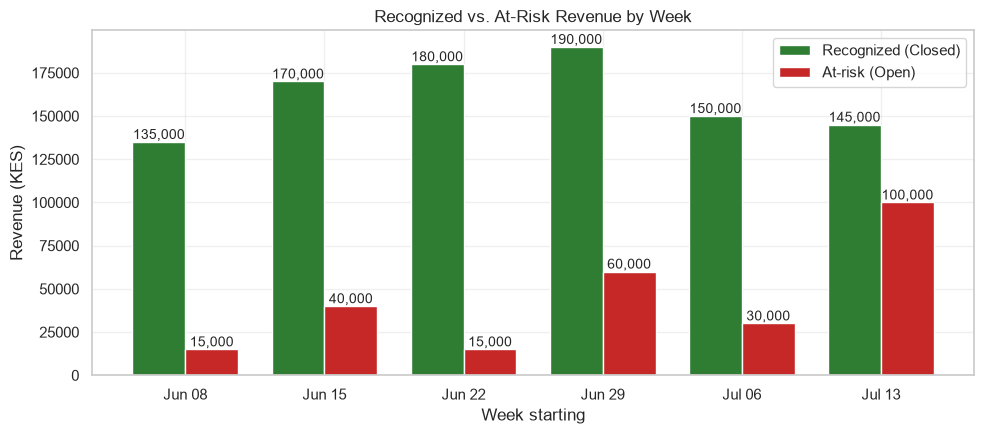

In [11]:
# --- Plot: recognized vs at-risk, side by side per week ---
x = np.arange(len(weekly_summary))
width = 0.38

fig, ax = plt.subplots()
ax.bar(x - width/2, weekly_summary["revenue"], width, label="Recognized (Closed)", color="#2E7D32")
ax.bar(x + width/2, weekly_summary["at_risk_revenue"], width, label="At-risk (Open)", color="#C62828")

# Value labels above each bar
for i, v in enumerate(weekly_summary["revenue"]):
    ax.text(i - width/2, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=10)
for i, v in enumerate(weekly_summary["at_risk_revenue"]):
    ax.text(i + width/2, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=10)

ax.set_title("Recognized vs. At-Risk Revenue by Week")
ax.set_xlabel("Week starting")
ax.set_ylabel(f"Revenue ({currency})")
ax.set_xticks(x)
ax.set_xticklabels(weekly_summary["week_start"].dt.strftime("%b %d"))
ax.legend()
plt.tight_layout()
plt.show()

<a id="b3"></a>
**B3.** Compute total weekly expenses (engineer salaries, prorated to a week using the assumptions file). A salary is a fixed cost per active engineer per week, whether or not they close a single ticket.

> Weekly expenses — prorated engineer salaries.\
> A salary is a fixed cost per ACTIVE engineer per week, regardless of tickets closed.\
"Active" = any engineer who has at least one ticket created in that week.

In [12]:
active_engineers_per_week = (
    tickets.groupby("week_start")["engineer"]
    .nunique()
    .reset_index()
    .rename(columns={"engineer": "active_engineers"})
)

active_engineers_per_week["weekly_expense"] = (
    (active_engineers_per_week["active_engineers"] * engineer_weekly_salary).round(2)
)

print(f"Weekly salary cost per engineer: {currency} {engineer_weekly_salary:,.2f}\n")
print(active_engineers_per_week.to_string(index=False))

total_expenses = active_engineers_per_week["weekly_expense"].sum()
print(f"\nTotal expenses across the period: {currency} {total_expenses:,.0f}")

Weekly salary cost per engineer: KES 6,928.41

week_start  active_engineers  weekly_expense
2026-06-08                12        83140.88
2026-06-15                11        76212.47
2026-06-22                12        83140.88
2026-06-29                10        69284.06
2026-07-06                 9        62355.66
2026-07-13                11        76212.47

Total expenses across the period: KES 450,346


<a id="b4"></a>
**B4.** Compute weekly profit (revenue − expenses) and plot it alongside revenue and expenses on one chart.

week_start  revenue  weekly_expense    profit
2026-06-08   135000        83140.88  51859.12
2026-06-15   170000        76212.47  93787.53
2026-06-22   180000        83140.88  96859.12
2026-06-29   190000        69284.06 120715.94
2026-07-06   150000        62355.66  87644.34
2026-07-13   145000        76212.47  68787.53

Total profit across the period: KES 519,654


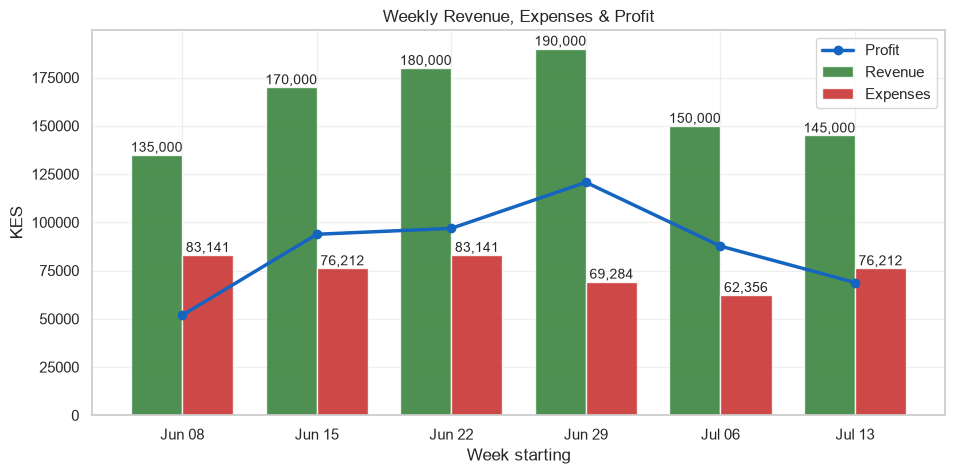

In [13]:
# Weekly profit = recognized revenue − salary expenses
# Merge the revenue table (B1/B2) with the expense table (B3) on week_start.

weekly_pnl = weekly_revenue.merge(
    active_engineers_per_week[["week_start", "weekly_expense"]],
    on="week_start",
    how="outer"
).fillna(0).sort_values("week_start").reset_index(drop=True)

weekly_pnl["profit"] = weekly_pnl["revenue"] - weekly_pnl["weekly_expense"]

print(weekly_pnl.to_string(index=False))

total_profit = weekly_pnl["profit"].sum()
print(f"\nTotal profit across the period: {currency} {total_profit:,.0f}")

# --- Plot: revenue, expenses, profit together ---
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(weekly_pnl))
width = 0.38
x_labels = weekly_pnl["week_start"].dt.strftime("%b %d")

ax.bar(x - width/2, weekly_pnl["revenue"], width, label="Revenue", color="#2E7D32", alpha=0.85)
ax.bar(x + width/2, weekly_pnl["weekly_expense"], width, label="Expenses", color="#C62828", alpha=0.85)

for i, v in enumerate(weekly_pnl["revenue"]):
    ax.text(i - width/2, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=10)
for i, v in enumerate(weekly_pnl["weekly_expense"]):
    ax.text(i + width/2, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=10)

ax.plot(x, weekly_pnl["profit"], marker="o", label="Profit", color="#1565C0", linewidth=2.5, zorder=3)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")

ax.set_title("Weekly Revenue, Expenses & Profit")
ax.set_xlabel("Week starting")
ax.set_ylabel(f"{currency}")
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
ax.legend()
# plt.tight_layout()
plt.show()

**Chart choice:** I opted for a combo chart instead of a simple line chart to display revenue and expenses as grouped bars — consistent with the bar treatment used in B1/B2 since they're discrete weekly totals — while profit is overlaid as a line to make its trend and any zero-crossings (weeks of loss) immediately visible without competing for space with the bar heights.

<a id="b5"></a>
**B5.** Compute week-over-week % change in revenue, expenses, and profit. Plot as a line chart.

week_start  revenue_pct_change  expense_pct_change  profit_pct_change
2026-06-08                 NaN                 NaN                NaN
2026-06-15           25.925926           -8.333337          80.850601
2026-06-22            5.882353            9.090914           3.275052
2026-06-29            5.555556          -16.666675          24.630432
2026-07-06          -21.052632           -9.999991         -27.396216
2026-07-13           -3.333333           22.222217         -21.515149


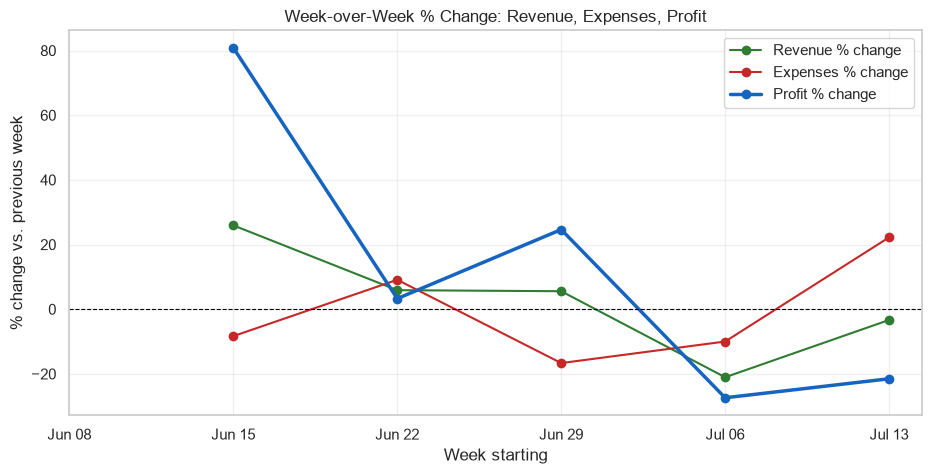

In [14]:
# Week-over-week % change in revenue, expenses, and profit

weekly_pnl_sorted = weekly_pnl.sort_values("week_start").reset_index(drop=True)

weekly_pnl_sorted["revenue_pct_change"] = weekly_pnl_sorted["revenue"].pct_change() * 100
weekly_pnl_sorted["expense_pct_change"] = weekly_pnl_sorted["weekly_expense"].pct_change() * 100
weekly_pnl_sorted["profit_pct_change"] = weekly_pnl_sorted["profit"].pct_change() * 100

print(weekly_pnl_sorted[[
    "week_start", "revenue_pct_change", "expense_pct_change", "profit_pct_change"
]].to_string(index=False))

# --- Plot ---
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(weekly_pnl_sorted))
x_labels = weekly_pnl_sorted["week_start"].dt.strftime("%b %d")

ax.plot(x, weekly_pnl_sorted["revenue_pct_change"], marker="o", label="Revenue % change", color="#2E7D32")
ax.plot(x, weekly_pnl_sorted["expense_pct_change"], marker="o", label="Expenses % change", color="#C62828")
ax.plot(x, weekly_pnl_sorted["profit_pct_change"], marker="o", label="Profit % change", color="#1565C0", linewidth=2.5)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")

ax.set_title("Week-over-Week % Change: Revenue, Expenses, Profit")
ax.set_xlabel("Week starting")
ax.set_ylabel("% change vs. previous week")
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
ax.legend()
# plt.tight_layout()
plt.show()

> **Note**: The first week's % change values are NaN (null) by design — pct_change() has no prior week to compare against for the earliest week in the dataset, so leaving it as NaN (rather than filling with 0) correctly signals "no comparison available" instead of falsely implying "no change occurred."

<a id="b6"></a>
**B6.** Plot cumulative profit across the period (running total).

week_start    profit  cumulative_profit
2026-06-08  51859.12           51859.12
2026-06-15  93787.53          145646.65
2026-06-22  96859.12          242505.77
2026-06-29 120715.94          363221.71
2026-07-06  87644.34          450866.05
2026-07-13  68787.53          519653.58


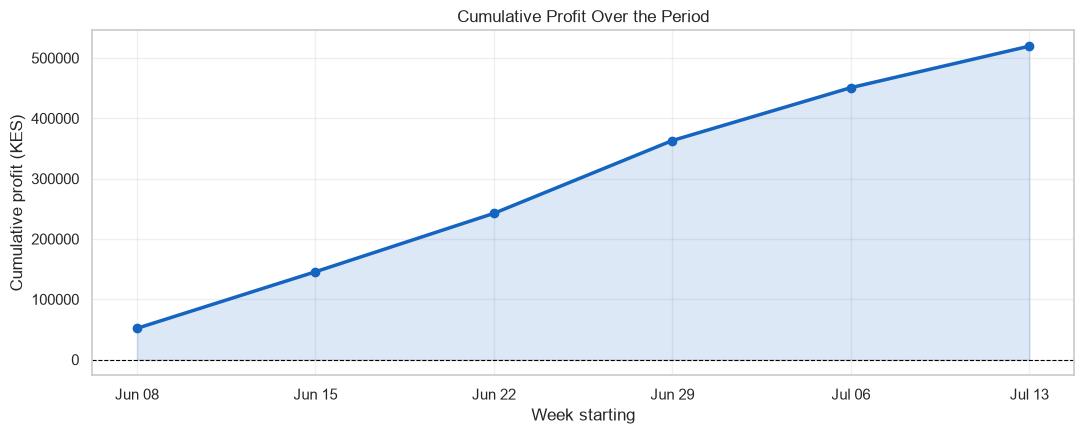

In [15]:
# Cumulative profit across the period (running total)

weekly_pnl_sorted["cumulative_profit"] = weekly_pnl_sorted["profit"].cumsum()

print(weekly_pnl_sorted[["week_start", "profit", "cumulative_profit"]].to_string(index=False))

# --- Plot ---
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(weekly_pnl_sorted))
x_labels = weekly_pnl_sorted["week_start"].dt.strftime("%b %d")

ax.plot(x, weekly_pnl_sorted["cumulative_profit"], marker="o", color="#1565C0", linewidth=2.5)
ax.fill_between(x, weekly_pnl_sorted["cumulative_profit"], 0, alpha=0.15, color="#1565C0")
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")

ax.set_title("Cumulative Profit Over the Period")
ax.set_xlabel("Week starting")
ax.set_ylabel(f"Cumulative profit ({currency})")
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
plt.tight_layout()
plt.show()

<a id="b7"></a>
**B7.** Project next week's revenue using a simple trend method of your choice (e.g. moving average or linear regression on the weekly series). Plot the historical weekly revenue plus your projection, and briefly justify your method.

In [16]:
# Project next week's revenue using linear regression on the weekly revenue trend
# Use week index as the independent variables - simpler and more robust than using raw dates, since it avoids scaling issues with datetime numbers
weeks_idx = np.arange(len(weekly_pnl_sorted)).reshape(-1,1) #turns the data into a 2D vector
revenue_series = weekly_pnl_sorted["revenue"].values

model = LinearRegression()
model.fit(weeks_idx, revenue_series)

# Obtain the slope and y-intercept
slope = model.coef_[0]
intercept = model.intercept_

# Project next week's revenue
next_week_idx = len(weekly_pnl_sorted)
projected_revenue = model.predict([[next_week_idx]])[0]
next_week_start = weekly_pnl_sorted["week_start"].max() + pd.Timedelta(weeks=1)

print(f"Linear fit: revenue ≈ ({slope} * week_idx) + {intercept:,.0f}")
print(f"Projected revenue for week starting {next_week_start.date()}: {currency} {projected_revenue:,.0f}")

Linear fit: revenue ≈ (3.734634920927519e-13 * week_idx) + 161,667
Projected revenue for week starting 2026-07-20: KES 161,667


In [17]:
# Moving average projection with a rolling period of 2 weeks, to compare against linear regression

MA_WINDOW = 2
moving_avg_projection = weekly_pnl_sorted["revenue"].tail(MA_WINDOW).mean()

print(f"Moving average (last {MA_WINDOW} weeks) projection: {currency} {moving_avg_projection:,.0f}")
print(f"Linear regression projection: {currency} {projected_revenue:,.0f}")
print(f"Difference: {currency} {projected_revenue - moving_avg_projection:,.0f}")

Moving average (last 2 weeks) projection: KES 147,500
Linear regression projection: KES 161,667
Difference: KES 14,167


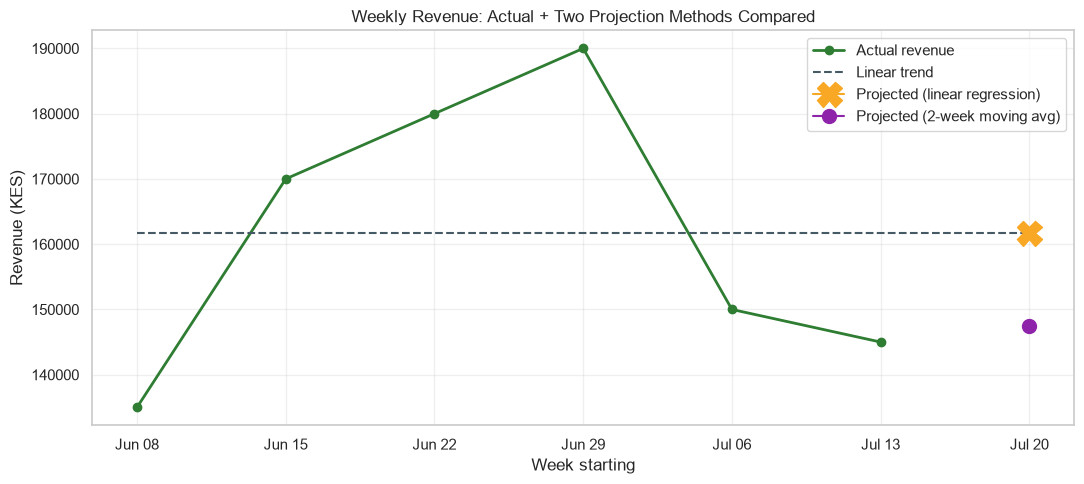

In [18]:
# --- Plot: actual revenue + both projections ---
fig, ax = plt.subplots(figsize=(11, 5))

x_hist = weeks_idx.flatten()
x_labels_hist = weekly_pnl_sorted["week_start"].dt.strftime("%b %d").tolist()
x_labels_full = x_labels_hist + [next_week_start.strftime("%b %d")]

x_fit = np.arange(len(weekly_pnl_sorted) + 1).reshape(-1, 1)
y_fit = model.predict(x_fit)

ax.plot(x_hist, revenue_series, marker="o", label="Actual revenue", color="#2E7D32", linewidth=2)
ax.plot(x_fit.flatten(), y_fit, linestyle="--", color="#455A64", label="Linear trend", linewidth=1.5)

ax.plot(next_week_idx, projected_revenue, marker="X", markersize=18, color="#F9A825",
        label="Projected (linear regression)", zorder=5)
ax.plot(next_week_idx, moving_avg_projection, marker="o", markersize=10, color="#8E24AA",
        label=f"Projected ({MA_WINDOW}-week moving avg)", zorder=5)

ax.set_title("Weekly Revenue: Actual + Two Projection Methods Compared")
ax.set_xlabel("Week starting")
ax.set_ylabel(f"Revenue ({currency})")
ax.set_xticks(np.arange(len(x_labels_full)))
ax.set_xticklabels(x_labels_full, rotation=0)
ax.legend()
plt.tight_layout()
plt.show()

> **Method comparison** — SMA vs. Linear Regression: I opted to use both a 2-week simple moving average and a linear regression for the next-week's revenue projection. The SMA produced a more conservative estimate of KES 147,500, while linear regression projected KES 161,667. On inspection, the linear regression's slope coefficient was negligibly small (3.73 × 10⁻¹³), meaning the fitted line is essentially flat — the model is really just returning its intercept (≈161,667) regardless of week index, rather than capturing any real upward or downward trend. This suggests revenue over the period has been roughly flat/stable rather than trending, which is why the regression collapses to a near-constant prediction. Given this, the SMA's KES 147,500 is arguably the more honest projection here, since it reflects actual recent values rather than a regression artifact with no real trend signal behind it.

<a id="section-c"></a>
### Section C — SLA & MTTR

<a id="c1"></a>
**C1.** Compute overall MTTR (Mean Time To Resolution, in hours) for closed tickets.

In [19]:
mttr_overall = closed_tickets["resolution_hours"].mean()

print(f"Overall MTTR (closed tickets): {mttr_overall:.2f} hours")
print(f"(based on {closed_tickets['resolution_hours'].notna().sum()} closed tickets with resolution data)")

# Sanity check: resolution_hours should be non-null for ALL closed tickets,
# and null for ALL open tickets — this validates our earlier A2 null-pattern assertion.
assert closed_tickets["resolution_hours"].notna().all(), "Found closed tickets with missing resolution_hours"

Overall MTTR (closed tickets): 19.62 hours
(based on 194 closed tickets with resolution data)


<a id="c2"></a>
**C2.** Plot the weekly MTTR trend — is resolution time getting better or worse?

week_start  mttr_hours
2026-06-08   17.825926
2026-06-15   18.876471
2026-06-22   21.080556
2026-06-29   20.057895
2026-07-06   19.023333
2026-07-13   20.372414


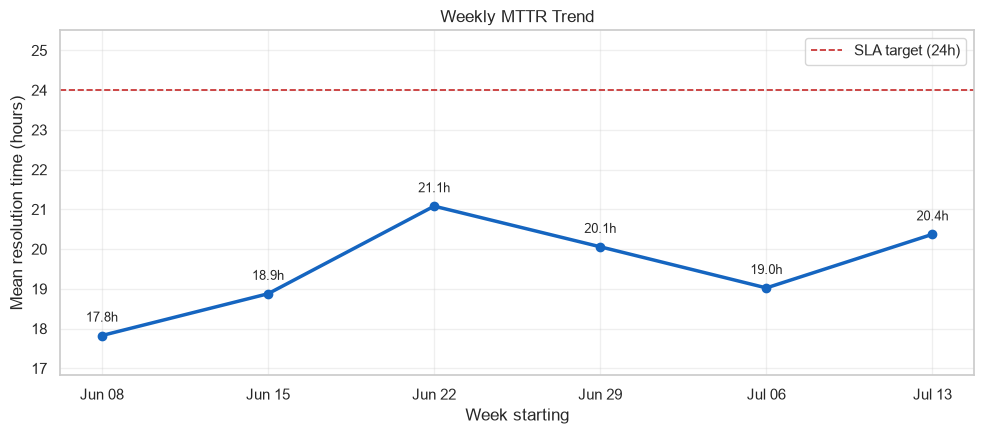

In [20]:
weekly_mttr = (
    closed_tickets.groupby("week_start")["resolution_hours"]
    .mean()
    .reset_index()
    .rename(columns={"resolution_hours": "mttr_hours"})
    .sort_values("week_start")
)

print(weekly_mttr.to_string(index=False))

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(weekly_mttr))
x_labels = weekly_mttr["week_start"].dt.strftime("%b %d")

ax.plot(x, weekly_mttr["mttr_hours"], marker="o", color="#1565C0", linewidth=2.5)
ax.axhline(sla_target_hours, color="#C62828", linestyle="--", linewidth=1.2, label=f"SLA target ({sla_target_hours}h)")

for i, v in enumerate(weekly_mttr["mttr_hours"]):
    ax.annotate(
        f"{v:.1f}h",
        xy=(i, v),
        xytext=(0, 10),              # offset 10 points straight up from the marker
        textcoords="offset points",
        ha="center", fontsize=9.5
    )

ax.set_title("Weekly MTTR Trend")
ax.set_xlabel("Week starting")
ax.set_ylabel("Mean resolution time (hours)")
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
ax.set_ylim(weekly_mttr["mttr_hours"].min() - 1, sla_target_hours + 1.5)
ax.legend()
plt.tight_layout()
plt.show()

> **MTTR trend**: Weekly mean resolution time fluctuates between ~18 and ~21 hours over the 6-week period, with no clear sustained improving or worsening trend — it rises through week 3, then levels off in the 19–20h range. Importantly, every week stays well within the 24-hour SLA target, so while resolution time isn't accelerating, it also isn't at risk of breaching SLA on average. The main signal here is stability, not a trend. It's worth checking SLA compliance (%) to see if this stability holds at the individual-ticket level too, or if the average is masking some tickets that blow past SLA even while the mean stays healthy.

<a id="c3"></a>
**C3.** Compute overall SLA compliance (% of closed tickets resolved within `sla_target_hours`). Plot the weekly compliance trend.

Overall SLA compliance: 74.23%
Tickets that breached SLA: 50 of 194 closed tickets

Weekly SLA compliance:
week_start  sla_compliance_pct
2026-06-08               81.48
2026-06-15               73.53
2026-06-22               63.89
2026-06-29               78.95
2026-07-06               76.67
2026-07-13               72.41


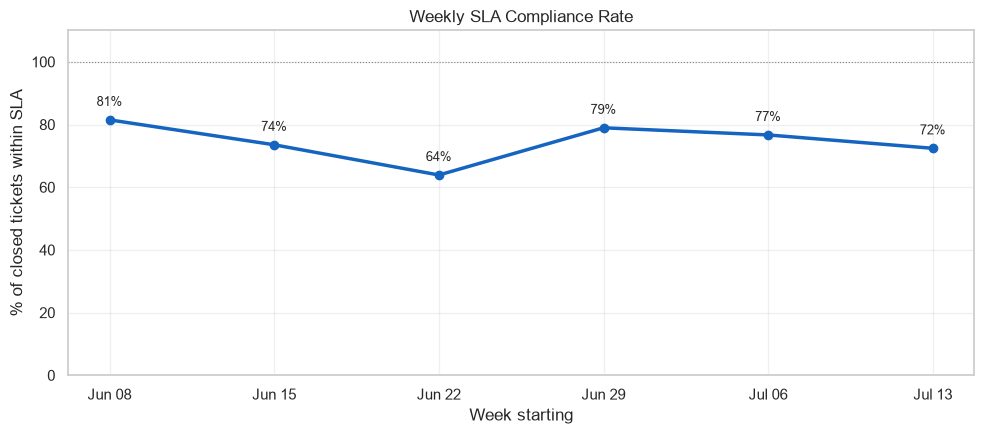

In [21]:
# % of closed tickets resolved within sla_target_hours
closed_tickets["within_sla"] = closed_tickets["resolution_hours"] <= sla_target_hours

overall_compliance = closed_tickets["within_sla"].mean() * 100
n_breached = (~closed_tickets["within_sla"]).sum()

print(f"Overall SLA compliance: {overall_compliance:.2f}%")
print(f"Tickets that breached SLA: {n_breached} of {len(closed_tickets)} closed tickets")

# --- Weekly compliance trend ---
weekly_sla = (
    closed_tickets.groupby("week_start")["within_sla"]
    .mean()
    .mul(100)
    .round(2)
    .reset_index()
    .rename(columns={"within_sla": "sla_compliance_pct"})
    .sort_values("week_start")
)

print("\nWeekly SLA compliance:")
print(weekly_sla.to_string(index=False))

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(weekly_sla))
x_labels = weekly_sla["week_start"].dt.strftime("%b %d")

ax.plot(x, weekly_sla["sla_compliance_pct"], marker="o", color="#1565C0", linewidth=2.5)
ax.axhline(100, color="gray", linewidth=0.8, linestyle=":")

for i, v in enumerate(weekly_sla["sla_compliance_pct"]):
    ax.annotate(
        f"{v:.0f}%",
        xy=(i, v),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center", fontsize=9.5
    )

ax.set_title("Weekly SLA Compliance Rate")
ax.set_xlabel("Week starting")
ax.set_ylabel("% of closed tickets within SLA")
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
ax.set_ylim(0, 110)
plt.tight_layout()
plt.show()

<a id="c4"></a>
**C4.** Plot the distribution of resolution hours (histogram). Identify and comment on any outliers.

count    194.000000
mean      19.617010
std        8.467541
min        4.100000
25%       13.300000
50%       17.950000
75%       24.250000
max       50.400000
Name: resolution_hours, dtype: float64

IQR outlier fences: [-3.1h, 40.7h]
Outlier tickets: 3 of 194 closed tickets (1.5%)

Outlier ticket details:
     engineer      region issue_type  resolution_hours week_start
Dennis Kiptoo     Western     Repair              50.4 2026-06-22
Dennis Kiptoo     Nairobi     Repair              48.5 2026-07-06
Dennis Kiptoo Rift Valley Relocation              46.4 2026-06-29


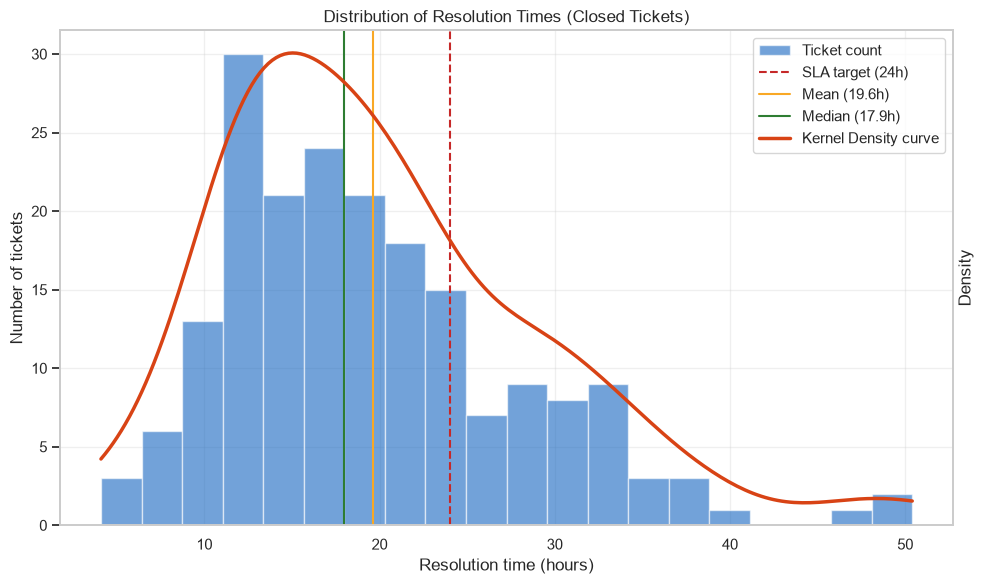

In [22]:
# --- Descriptive stats first to contextualize the histogram ---
res_hours = closed_tickets["resolution_hours"]
print(res_hours.describe())

# IQR-based outlier detection — standard, robust method that doesn't assume
# a normal distribution (resolution times are typically right-skewed).
q1, q3 = res_hours.quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = closed_tickets[(res_hours < lower_bound) | (res_hours > upper_bound)]
print(f"\nIQR outlier fences: [{lower_bound:.1f}h, {upper_bound:.1f}h]")
print(f"Outlier tickets: {len(outliers)} of {len(closed_tickets)} closed tickets ({len(outliers)/len(closed_tickets)*100:.1f}%)")

if len(outliers) > 0:
    print("\nOutlier ticket details:")
    print(outliers[["engineer", "region", "issue_type", "resolution_hours", "week_start"]]
          .sort_values("resolution_hours", ascending=False)
          .to_string(index=False))

# --- Plot ---
fig, ax1 = plt.subplots(figsize=(10, 6))

# Histogram on primary axis (counts)
ax1.hist(res_hours, bins=20, color="#1565C0", alpha=0.6, edgecolor="white", label="Ticket count")
ax1.set_xlabel("Resolution time (hours)")
ax1.set_ylabel("Number of tickets")

# KDE curve on secondary axis (density) — same x-axis, different y-scale
ax2 = ax1.twinx()
kde = gaussian_kde(res_hours.dropna())
x_range = np.linspace(res_hours.min(), res_hours.max(), 200)
ax2.plot(x_range, kde(x_range), color="#D84315", linewidth=2.5, label="Kernel Density curve")
ax2.set_ylabel("Density")
ax2.set_yticks([])

# Reference lines (SLA, mean, median) on the primary axis
ax1.axvline(sla_target_hours, color="#C62828", linestyle="--", linewidth=1.5, label=f"SLA target ({sla_target_hours}h)")
ax1.axvline(res_hours.mean(), color="#F9A825", linestyle="-", linewidth=1.5, label=f"Mean ({res_hours.mean():.1f}h)")
ax1.axvline(res_hours.median(), color="#2E7D32", linestyle="-", linewidth=1.5, label=f"Median ({res_hours.median():.1f}h)")

# Combine legends from both axes into one
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

ax1.set_title("Distribution of Resolution Times (Closed Tickets)")
plt.tight_layout()
plt.show()

> **Distribution shape:** Resolution times are right-skewed — most tickets cluster in the 10–20 hour range (the mode sits around 13–17h), but a long tail stretches out to 50 hours. This skew is confirmed numerically: the mean (19.6h) sits above the median (17.9h), meaning a minority of slow tickets are pulling the average upward — the "typical" ticket resolves faster than the mean alone suggests. The bulk of the distribution sits comfortably under the 24-hour SLA line, but the tail extends well past it, which is exactly what C3's compliance rate is quantifying.

> **Outliers:** Using IQR bounds, 3 of 194 closed tickets (1.5%) are flagged as outliers, all resolving in 46–50 hours — roughly double the SLA target. Notably, all three outlier tickets belong to the same engineer, Dennis Kiptoo, spanning three different regions (Western, Nairobi, Rift Valley) and two issue types (Repair, Relocation). Since the outliers aren't concentrated in one region or issue type but are concentrated in one engineer, this points toward an individual performance or workload signal rather than a systemic regional/issue-type problem — worth cross-referencing against Section D (engineer performance) rather than treating as isolated data noise.

> **Possible driver — travel/dispatch pattern:** Dennis Kiptoo's three outlier tickets span three different regions (Western, Nairobi, Rift Valley), which raises the possibility that cross-region travel time is contributing to the elevated resolution times — the dataset doesn't include travel or distance data to confirm this directly, but if resolution hours is measured door-to-door, dispatching one engineer across a wide geographic spread rather than a single home region is a plausible operational factor. This is a hypothesis worth investigating with dispatch/routing data, not a confirmed cause — the sample here is only 3 tickets, and alternative explanations (workload volume, issue complexity, or general variance) can't be ruled out with what's available.

> **Note on the density curve:** The red line overlaid on the histogram is a kernel density estimate (KDE) — a smoothed version of the same distribution shown by the bars, useful for seeing the overall shape (skew, peak location, tail behavior) without the visual noise of individual bin heights. It sits on its own y-axis (density, not ticket count), which is why that axis has no visible scale — the curve's absolute height isn't meaningful on its own, only its shape and where it peaks or tails off relative to the histogram bars beneath it.

<a id="c5"></a>
**C5.** Plot the backlog (cumulative open tickets) over time. Is it growing or shrinking?

week_start  created_cumulative  closed_cumulative  backlog
2026-06-08                  30                 26        4
2026-06-15                  72                 53       19
2026-06-22                 111                 91       20
2026-06-29                 161                131       30
2026-07-06                 197                163       34
2026-07-13                 246                194       52


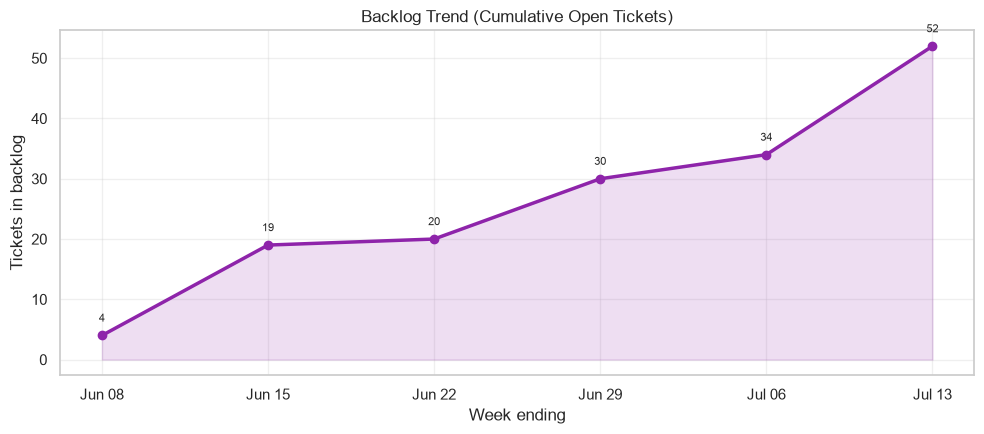

In [23]:
# Backlog at the end of week X = (tickets created up to week X) - (tickets closed up to week X)
overall_max_date = max(tickets["created_date"].max(), tickets["closed_date"].max())

all_weeks = sorted(tickets["week_start"].unique())

backlog_rows = []
for i, week in enumerate(all_weeks):
    created_so_far = (tickets["week_start"] <= week).sum()

    natural_week_end = week + pd.Timedelta(days=6, hours=23, minutes=59, seconds=59)

    # Only the LAST week needs extending — earlier weeks should keep their natural boundary
    if i == len(all_weeks) - 1:
        week_end = overall_max_date
    else:
        week_end = natural_week_end

    closed_so_far = (tickets["closed_date"] <= week_end).sum()
    
    backlog_rows.append({
        "week_start": week,
        "created_cumulative": created_so_far,
        "closed_cumulative": closed_so_far,
        "backlog": created_so_far - closed_so_far
    })

backlog_df = pd.DataFrame(backlog_rows)
print(backlog_df.to_string(index=False))

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(backlog_df))
x_labels = backlog_df["week_start"].dt.strftime("%b %d")

ax.plot(x, backlog_df["backlog"], marker="o", color="#8E24AA", linewidth=2.5)
ax.fill_between(x, backlog_df["backlog"], 0, alpha=0.15, color="#8E24AA")

for i, v in enumerate(backlog_df["backlog"]):
    ax.annotate(f"{v}", xy=(i, v), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8)

ax.set_title("Backlog Trend (Cumulative Open Tickets)")
ax.set_xlabel("Week ending")
ax.set_ylabel("Tickets in backlog")
ax.set_xticks(x)
ax.set_xticklabels(x_labels)
plt.tight_layout()
plt.show()

> **Backlog trend:** The backlog has grown every single week of the 6-week period — from 4 tickets outstanding after week 1 to 52 by week 6, a more than 13x increase. The growth isn't perfectly steady, it's exponentially accelerating: the backlog surged early in the second week to 19 tickets then briefly plateaued going into week 3 (19 → 20) , then accelerated again through the second half of the period with the largest single jump coming in the final week (34 → 52). This pattern, combined with C2/C3 showing individual ticket resolution times and SLA compliance holding reasonably steady, points to a **capacity problem rather than a skill or speed problem:** the team isn't getting worse at resolving tickets once they're picked up, but new tickets are arriving faster than the team can close them, and the gap is widening. If this trajectory continues past the 6-week window, backlog — and therefore at-risk revenue — will keep compounding.

> **Data quality fix:** Initial backlog calculations used week_start + 6 days (midnight) as the week-end boundary, but closed date includes time-of-day values — so tickets closed later in the day on the final Sunday, or into the following Monday before the next week's data cutoff, were being excluded from closed_cumulative and miscounted as backlog. Adjusting week_end to the full end of day (23:59:59) corrects this and brings the final week's backlog in line with the actual open-ticket count confirmed in A2 (52).

<a id="section-d"></a>
### Section D — Engineer Performance & Profitability

<a id="d1"></a>
**D1.** Plot ticket volume per engineer (open + closed), sorted descending.

       engineer  ticket_count
   Brian Otieno            34
Esther Nyambura            31
  Faith Wanjiru            30
   Linda Chebet            29
    Kevin Mutua            25
  Grace Achieng            23
  Dennis Kiptoo            18
  Samuel Wafula            18
  Sarah Njoroge            17
   Peter Omondi            13
 Josephine Auma             6
  Michael Kamau             2


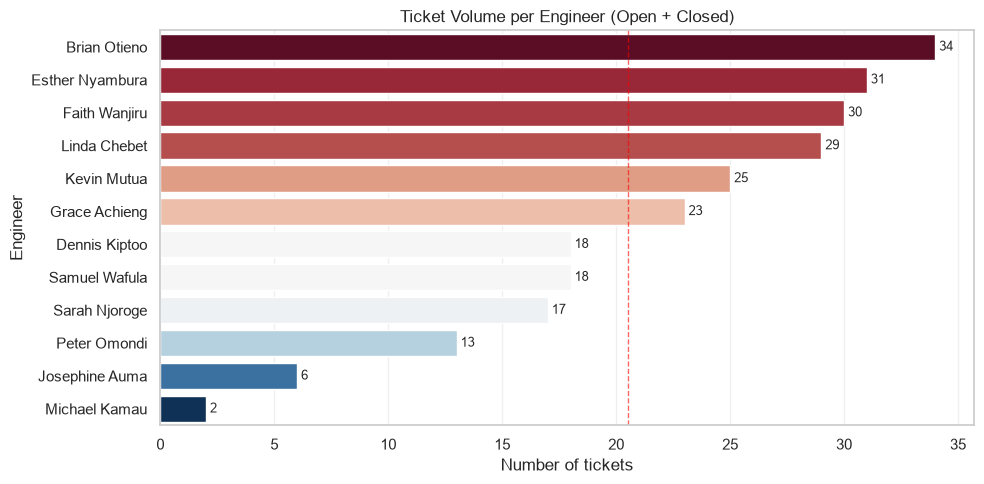

In [24]:
# Ticket volume per engineer (open + closed combined), sorted descending
engineer_volume = (
    tickets.groupby("engineer")
    .size()
    .reset_index(name="ticket_count")
    .sort_values("ticket_count", ascending=False)
)

print(engineer_volume.to_string(index=False))

avg_volume = engineer_volume["ticket_count"].mean()

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=engineer_volume,
    y="engineer",
    x="ticket_count",
    order=engineer_volume["engineer"],
    hue="ticket_count",
    palette="RdBu_r",
    legend=False,
    ax=ax
)

ax.axvline(avg_volume, color="red", linestyle="--", linewidth=1, alpha=0.6,
           label=f"Average ({avg_volume:.1f})")

for i, v in enumerate(engineer_volume["ticket_count"]):
    ax.text(v, i, f" {v}", va="center", fontsize=9)

ax.set_title("Ticket Volume per Engineer (Open + Closed)")
ax.set_xlabel("Number of tickets")
ax.set_ylabel("Engineer")
plt.tight_layout()
plt.show()

> **Chart choice:** A seaborn barplot with a diverging color palette was used instead of a single-color matplotlib bar, so ticket volume is communicated through two visual channels at once — bar length and color intensity — making it faster to spot the highest and lowest volume engineers at a glance rather than reading bar lengths individually.

<a id="d2"></a>
**D2.** For each engineer, compute tickets closed, revenue generated, prorated salary cost over the period, and net contribution (revenue − cost). Plot engineers ranked by net contribution, colored by profit vs. loss.

       engineer  tickets_closed  revenue  active_weeks  salary_cost  net_contribution
   Brian Otieno              29   145000             6 41570.438799         103429.56
  Faith Wanjiru              24   120000             6 41570.438799          78429.56
Esther Nyambura              23   115000             6 41570.438799          73429.56
   Linda Chebet              22   110000             6 41570.438799          68429.56
  Grace Achieng              21   105000             6 41570.438799          63429.56
    Kevin Mutua              19    95000             6 41570.438799          53429.56
   Peter Omondi              12    60000             5 34642.032333          25357.97
  Dennis Kiptoo              13    65000             6 41570.438799          23429.56
  Sarah Njoroge              13    65000             6 41570.438799          23429.56
  Samuel Wafula              13    65000             6 41570.438799          23429.56
 Josephine Auma               4    20000             4

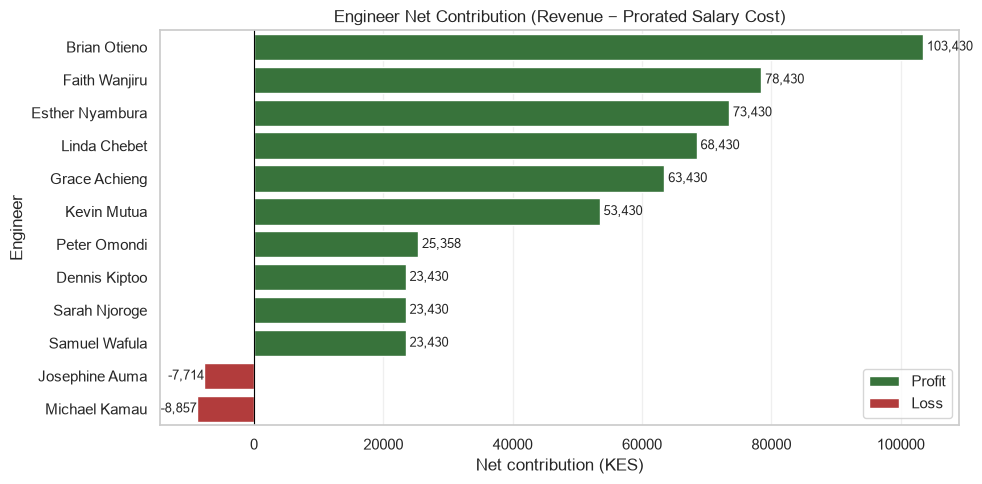

In [25]:
# --- Tickets closed & revenue per engineer ---
engineer_revenue = (
    closed_tickets.groupby("engineer")
    .agg(tickets_closed=("engineer", "size"), revenue=("revenue", "sum"))
    .reset_index()
)
# --- Prorated salary cost per engineer ---
# Cost = number of weeks that engineer was "active" (per our B3 definition:
# had ≥1 ticket created that week) * weekly salary. This keeps the cost
# calculation consistent with the same active-engineer logic used in B3,
# rather than assuming every engineer worked all 6 weeks.
engineer_active_weeks = (
    tickets.groupby("engineer")["week_start"]
    .nunique()
    .reset_index(name="active_weeks")
)

engineer_active_weeks["salary_cost"] = engineer_active_weeks["active_weeks"] * engineer_weekly_salary

# --- Combine ---
engineer_perf = engineer_revenue.merge(engineer_active_weeks, on="engineer", how="outer").fillna(0)
engineer_perf["net_contribution"] = (engineer_perf["revenue"] - engineer_perf["salary_cost"]).round(2)
engineer_perf = engineer_perf.sort_values("net_contribution", ascending=False)

print(engineer_perf.to_string(index=False))

# --- Plot: ranked by net contribution, colored by profit vs loss ---
engineer_perf["outcome"] = np.where(engineer_perf["net_contribution"] >= 0, "Profit", "Loss")

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=engineer_perf,
    y="engineer",
    x="net_contribution",
    order=engineer_perf["engineer"],   # preserve the net_contribution sort
    hue="outcome",
    palette={"Profit": "#2E7D32", "Loss": "#C62828"},
    dodge=False,
    ax=ax
)

ax.axvline(0, color="black", linewidth=0.8)

for i, v in enumerate(engineer_perf["net_contribution"]):
    ax.text(v, i, f" {v:,.0f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)

ax.set_title("Engineer Net Contribution (Revenue − Prorated Salary Cost)")
ax.set_xlabel(f"Net contribution ({currency})")
ax.set_ylabel("Engineer")
ax.legend(title="")
plt.tight_layout()
plt.show()

**Chart choice:** Seaborn's hue parameter maps net contribution directly to a labeled category (Profit / Loss) with an automatic legend, which is more explicit than matplotlib's approach of manually assigning colors via a lambda and building a custom legend by hand. Since D2's chart is specifically asked to be "colored by profit vs. loss," seaborn's category-based coloring is a more natural fit than a continuous gradient (which was more appropriate for D1's workload-intensity view).

<a id="d3"></a>
**D3.** Explicitly answer: which engineers are net POSITIVE (bringing in more than they cost) and which are net NEGATIVE (at a loss)?

In [26]:
# D3: Which engineers are net POSITIVE vs. net NEGATIVE?

net_positive = engineer_perf[engineer_perf["net_contribution"] >= 0].sort_values("net_contribution", ascending=False)
net_negative = engineer_perf[engineer_perf["net_contribution"] < 0].sort_values("net_contribution")

print(f"NET POSITIVE engineers ({len(net_positive)}):")
print(net_positive[["engineer", "tickets_closed", "revenue", "salary_cost", "net_contribution"]].to_string(index=False))

print(f"\nNET NEGATIVE engineers ({len(net_negative)}):")
if len(net_negative) > 0:
    print(net_negative[["engineer", "tickets_closed", "revenue", "salary_cost", "net_contribution"]].to_string(index=False))
else:
    print("None — every engineer is net positive over the period.")

NET POSITIVE engineers (10):
       engineer  tickets_closed  revenue  salary_cost  net_contribution
   Brian Otieno              29   145000 41570.438799         103429.56
  Faith Wanjiru              24   120000 41570.438799          78429.56
Esther Nyambura              23   115000 41570.438799          73429.56
   Linda Chebet              22   110000 41570.438799          68429.56
  Grace Achieng              21   105000 41570.438799          63429.56
    Kevin Mutua              19    95000 41570.438799          53429.56
   Peter Omondi              12    60000 34642.032333          25357.97
  Dennis Kiptoo              13    65000 41570.438799          23429.56
  Sarah Njoroge              13    65000 41570.438799          23429.56
  Samuel Wafula              13    65000 41570.438799          23429.56

NET NEGATIVE engineers (2):
      engineer  tickets_closed  revenue  salary_cost  net_contribution
 Michael Kamau               1     5000 13856.812933          -8856.81
Josephin

In [27]:
print(f"{currency} {net_positive['net_contribution'].sum().round(2)}")

KES 536224.01


> **Net positive/negative summary:** 10 of 12 engineers are net positive over the period, contributing a combined KES 536,224. Only 2 engineers are net negative — Michael Kamau (−KES 8,857) and Josephine Auma (−KES 7,714) — and in both cases the driver is clearly low ticket volume relative to salary cost, not resolution speed: Michael closed just 1 ticket over the period, and Josephine closed only 4, while every net-positive engineer closed at least 12. Their salary costs (KES 13,857 and KES 27,714) reflect fewer active weeks than most engineers, but even prorated down, their ticket output wasn't enough to cover that reduced cost — suggesting these are engineers who were active for only a short stretch of the 6-week window rather than chronic underperformers over the full period.

> **NB:** Dennis Kiptoo — flagged in C4 for having all 3 of the outlier long-resolution tickets — is still comfortably net positive (KES 23,430, tied for the same contribution as two other engineers), meaning his slower resolution times on those specific tickets haven't translated into an overall profitability problem. This decouples the two findings: Dennis's outlier tickets are a speed/SLA-risk concern worth monitoring, but not currently a profitability concern — while Michael and Josephine's negative contribution looks like a volume/tenure issue, unrelated to resolution speed.

<a id="d4"></a>
**D4.** Plot each engineer's SLA compliance rate against their ticket volume (scatter). Is there a relationship between speed/quality and how much workload someone carries?

In [28]:
engineer_sla = (
    closed_tickets.groupby("engineer")["within_sla"]
    .mean()
    .mul(100)
    .round(2)
    .reset_index()
    .rename(columns={"within_sla": "sla_compliance_pct"})
)
# Use total ticket volume (open + closed) from D1 as the workload measure,
# not just closed tickets — workload should reflect everything on an
# engineer's plate, not just what they've finished.
engineer_scatter = engineer_volume.merge(engineer_sla, on="engineer", how="left")
print(engineer_scatter.to_string(index=False))

       engineer  ticket_count  sla_compliance_pct
   Brian Otieno            34              100.00
Esther Nyambura            31               39.13
  Faith Wanjiru            30              100.00
   Linda Chebet            29               81.82
    Kevin Mutua            25               84.21
  Grace Achieng            23               85.71
  Dennis Kiptoo            18               23.08
  Samuel Wafula            18               61.54
  Sarah Njoroge            17               69.23
   Peter Omondi            13               58.33
 Josephine Auma             6               50.00
  Michael Kamau             2              100.00


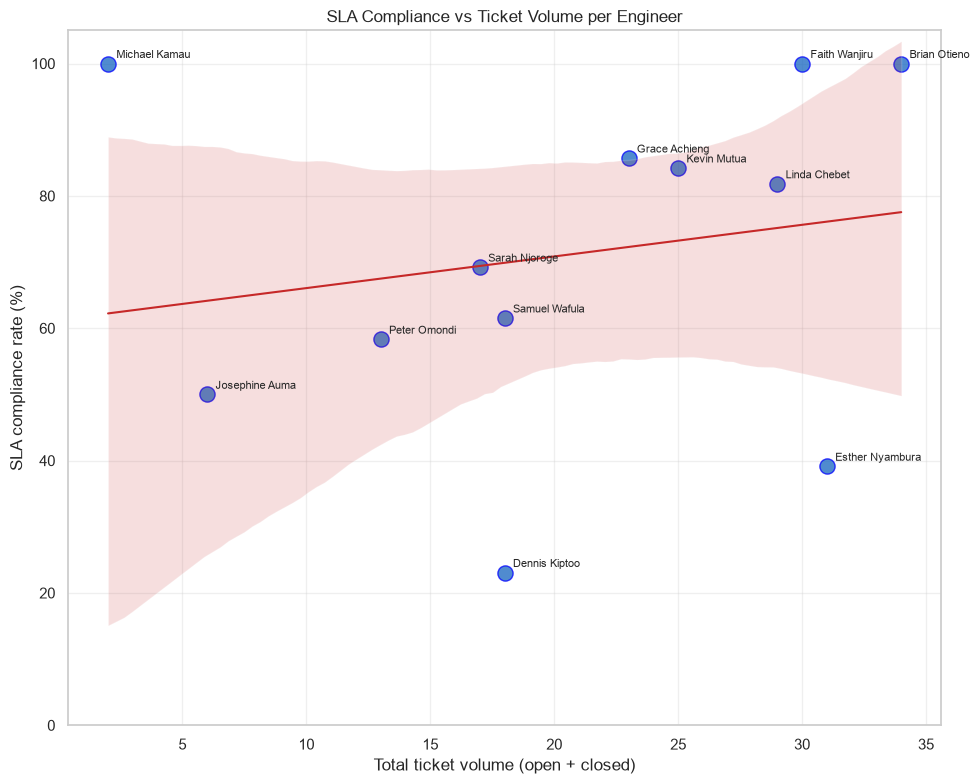

Correlation (ticket volume vs. SLA compliance): 0.19


In [29]:
#-- Plot --
fig, ax = plt.subplots(figsize=(10, 8))

sns.regplot(
    data=engineer_scatter,
    x="ticket_count",
    y="sla_compliance_pct",
    scatter_kws={"s": 120, "color": "#1565C0", "alpha": 0.75, "edgecolor": "blue"},
    line_kws={"color": "#C62828", "linewidth": 1.5},
    ax=ax
)

for _, row in engineer_scatter.iterrows():
    ax.annotate(
        row["engineer"],
        xy=(row["ticket_count"], row["sla_compliance_pct"]),
        xytext=(6, 4), textcoords="offset points", fontsize=8
    )

ax.set_title("SLA Compliance vs Ticket Volume per Engineer")
ax.set_xlabel("Total ticket volume (open + closed)")
ax.set_ylabel("SLA compliance rate (%)")
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()

correlation = engineer_scatter["ticket_count"].corr(engineer_scatter["sla_compliance_pct"])
print(f"Correlation (ticket volume vs. SLA compliance): {correlation:.2f}")

> **Is there a relationship between workload and SLA quality?** The fitted trend is weakly positive (more tickets ≈ marginally higher compliance), but the wide confidence band — especially at the extremes — shows this trend is not well-supported by only 12 engineers; it should be read as inconclusive rather than a real pattern. The more meaningful signal comes from individual outliers: Dennis Kiptoo (consistent with the C4 finding) and Esther Nyambura both sit well below the trend line, but Esther is the more urgent case — she combines high ticket volume (~31, the second-highest of any engineer) with low SLA compliance (~39%), meaning a large share of total workload is being handled at below-average quality. Michael Kamau's 100% compliance is likely a small-sample artifact (only ~2 tickets) rather than evidence of strong performance, consistent with his net-negative contribution in D3.

<a id="d5"></a>
**D5. (written)** If you had to recommend one staffing change (retrain, reassign workload, let go, promote/reward) based only on this data, what would it be and why? Acknowledge the limits of a 6-week sample.

>
**Recommendations:**
>
**Reassign/investigate Esther Nyambura's workload:** Of the two outlier engineers identified in this analysis, Esther Nyambura presents the more urgent operational risk. She carries the second-highest ticket volume of any engineer (~31 tickets) but has the lowest SLA compliance rate observed (~39%) — well below the fitted trend line in D4, meaning a large share of total team output is currently being delivered at below-average quality. This differs from Dennis Kiptoo, whose SLA issues (flagged in C4) appear concentrated in 3 specific long-resolution tickets tied to cross-region assignments, and who remains net-positive on revenue (D3) — Dennis's issue looks more like a routing/dispatch pattern than a broad quality problem. Esther's low compliance across a high volume of tickets is a different shape of risk: either she's overloaded relative to what one engineer can sustainably deliver, or there's a skill/process gap worth investigating directly. My recommendation is to reduce Esther's ticket load and pair the change with a direct conversation to understand whether the cause is volume, complexity of assigned tickets, or something else — rather than reassigning tickets away from her permanently without knowing the root cause.
>
**Potentially promote Brian Otieno:** On the positive end, Brian Otieno stands out as the strongest performer in the dataset on every dimension simultaneously — the highest ticket volume of any engineer, 100% SLA compliance, and the highest net contribution (~KES 103,430). Unlike Michael Kamau, whose 100% compliance (D4) is almost certainly a small-sample artifact given his very low ticket count, Brian's perfect compliance holds up across the largest workload on the team, making it a genuine signal of consistent quality rather than a statistical fluke. This combination makes Brian a clear candidate for recognition, a bonus, or a mentorship-style promotion — potentially pairing him with lower-compliance, high-volume engineers like Esther to share whatever practices are keeping his resolution times consistently within SLA.
>
I'd stop short of recommending anything punitive for Michael Kamau or Josephine Auma (both net-negative in D3) — their low ticket counts (1 and 4, respectively) look more consistent with short tenure within the 6-week window than underperformance, and Michael's 100% SLA compliance is almost certainly a small-sample artifact rather than a real signal.
>
**Caveat:** Six weeks is a short window to draw firm conclusions about any individual engineer — normal week-to-week variance, onboarding timing, or a single unusual ticket can all distort a 6-week snapshot. I'd treat this as a hypothesis to validate with a longer observation period or a direct conversation, not a final performance verdict.

<a id="section-e"></a>
### Section E — Recurrence / Account Analysis

<a id="e1"></a>
**E1.** Identify accounts that appear on more than one ticket ("recurring accounts"). What % of all tickets belong to a recurring account?

In [30]:
account_ticket_counts = tickets.groupby("account_number").size().reset_index(name="ticket_count")

recurring_accounts = account_ticket_counts[account_ticket_counts["ticket_count"] > 1]

n_recurring = len(recurring_accounts)
n_total_accounts = len(account_ticket_counts)
tickets_from_recurring = recurring_accounts["ticket_count"].sum()
pct_tickets_from_recurring = tickets_from_recurring / len(tickets) * 100

print(f"Total unique accounts: {n_total_accounts}")
print(f"Recurring accounts (>1 ticket): {n_recurring} ({n_recurring / n_total_accounts * 100:.1f}% of all accounts)")
print(f"Tickets from recurring accounts: {tickets_from_recurring} of {len(tickets)} total ({pct_tickets_from_recurring:.1f}%)")

print("\nRecurring account breakdown:")
print(recurring_accounts.sort_values("ticket_count", ascending=False).to_string(index=False))

Total unique accounts: 221
Recurring accounts (>1 ticket): 15 (6.8% of all accounts)
Tickets from recurring accounts: 40 of 246 total (16.3%)

Recurring account breakdown:
account_number  ticket_count
      ACC20008             5
      ACC20002             4
      ACC20004             3
      ACC20005             3
      ACC20013             3
      ACC20012             3
      ACC20003             3
      ACC20006             2
      ACC20001             2
      ACC20000             2
      ACC20007             2
      ACC20010             2
      ACC20009             2
      ACC20011             2
      ACC20014             2


<a id="e2"></a>
**E2.** Plot the top 10 accounts by ticket count.

account_number  ticket_count
      ACC20008             5
      ACC20002             4
      ACC20004             3
      ACC20005             3
      ACC20003             3
      ACC20012             3
      ACC20013             3
      ACC20001             2
      ACC20000             2
      ACC20007             2


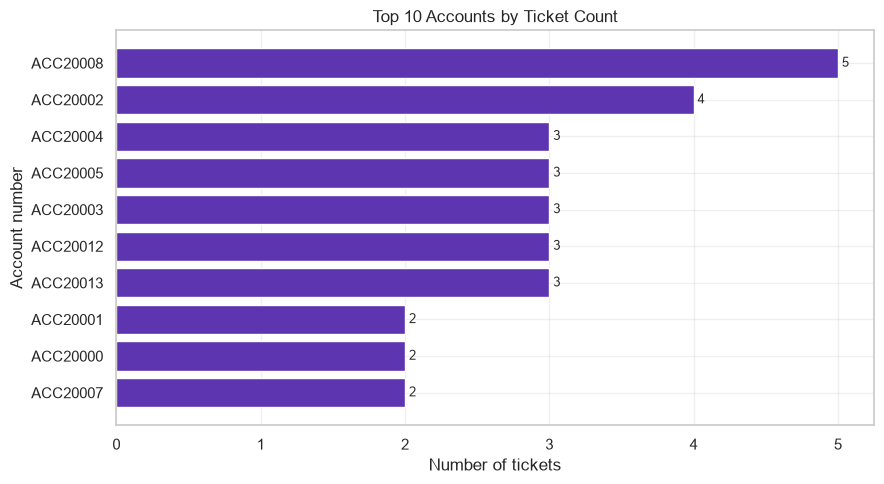

In [31]:
top_10_accounts = account_ticket_counts.sort_values("ticket_count", ascending=False).head(10)

print(top_10_accounts.to_string(index=False))

# --- Plot ---
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_10_accounts["account_number"].astype(str), top_10_accounts["ticket_count"], color="#5E35B1")
ax.invert_yaxis()

for i, v in enumerate(top_10_accounts["ticket_count"]):
    ax.text(v, i, f" {v}", va="center", fontsize=9)

ax.set_title("Top 10 Accounts by Ticket Count")
ax.set_xlabel("Number of tickets")
ax.set_ylabel("Account number")
plt.tight_layout()
plt.show()

<a id="e3"></a>
**E3. (written)** What could repeated tickets from the same account indicate operationally (e.g. a faulty install, a chronic outage area, customer behavior)? What would you want to investigate next?

> A few operational explanations are plausible, and they point to different fixes: repeated tickets could reflect a faulty install that wasn't fully resolved the first time (each new ticket is really the same underlying problem resurfacing), a chronic outage-prone area where infrastructure issues affect the same account repeatedly regardless of individual fixes, or customer behavior — some accounts may simply generate more service requests due to usage patterns, equipment sensitivity, or a lower threshold for reporting issues.

> With the top account (ACC20008) at only 5 tickets and no single account dramatically outpacing the rest, this doesn't look like one severe outlier account — it's a broader, moderate pattern of recurrence spread across several accounts. That's actually a more useful signal than a single extreme case would be: it suggests recurrence might be a systemic issue-type or regional pattern rather than one bad install or one difficult customer.

> **What I'd investigate next:** cross-referencing the recurring accounts against issue_type and region would clarify whether repeat tickets cluster around a specific problem type (e.g. mostly Repair tickets, suggesting equipment reliability) or a specific region (suggesting infrastructure quality in that area) — either finding would justify a different fix, from equipment audits to infrastructure investment. 

<a id="section-f"></a>
### Section F — Regional View (bonus depth)

<a id="f1"></a>
**F1.** Compare revenue, SLA compliance, and MTTR across regions.

     region  revenue  sla_compliance_pct  mttr_hours
    Nairobi   455000               79.12       18.78
      Coast   270000               74.07       18.05
Rift Valley   140000               64.29       23.22
    Western   105000               66.67       22.45


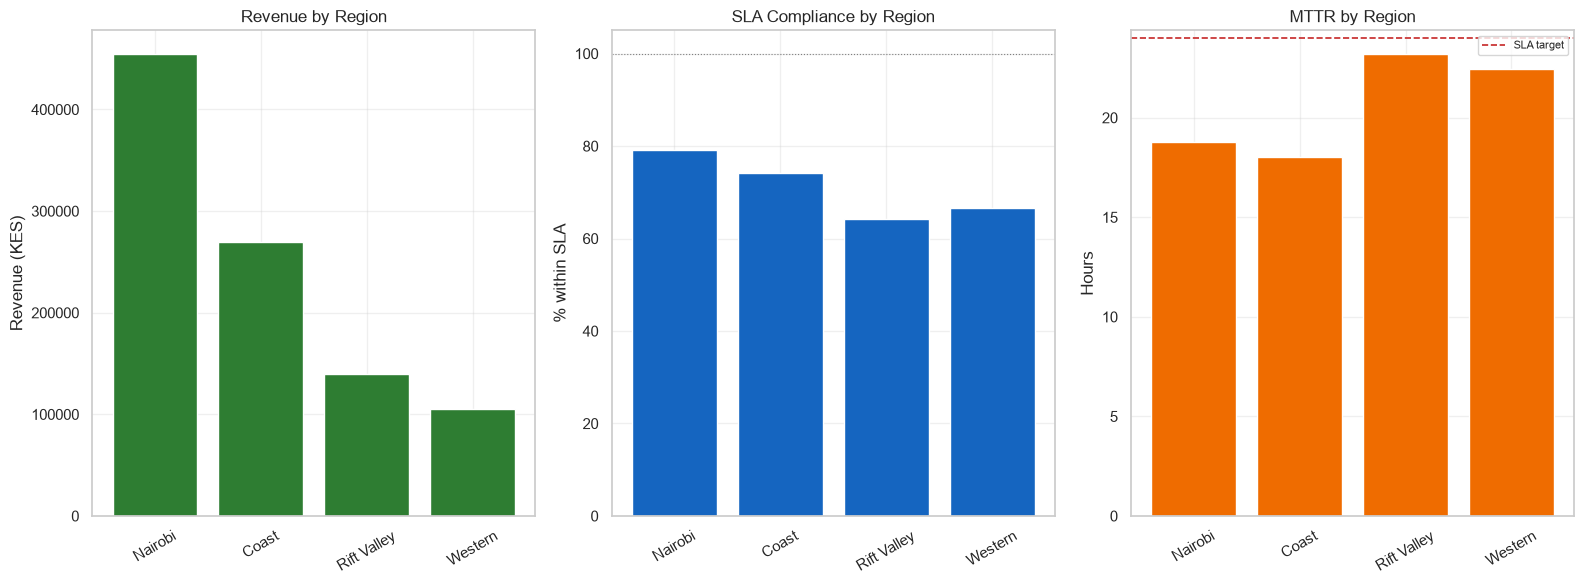

In [32]:
# --- Revenue by region (closed tickets only) ---
region_revenue = closed_tickets.groupby("region")["revenue"].sum().reset_index()

# --- SLA compliance by region (closed tickets only) ---
region_sla = (
    closed_tickets.groupby("region")["within_sla"]
    .mean()
    .mul(100)
    .round(2)
    .reset_index()
    .rename(columns={"within_sla": "sla_compliance_pct"})
)

# --- MTTR by region (closed tickets only) ---
region_mttr = (
    closed_tickets.groupby("region")["resolution_hours"]
    .mean()
    .round(2)
    .reset_index()
    .rename(columns={"resolution_hours": "mttr_hours"})
)

# --- Combine into one summary table ---
region_summary = region_revenue.merge(region_sla, on="region").merge(region_mttr, on="region")
region_summary = region_summary.sort_values("revenue", ascending=False)

print(region_summary.to_string(index=False))

# --- Plot: three metrics side by side ---
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].bar(region_summary["region"], region_summary["revenue"], color="#2E7D32")
axes[0].set_title("Revenue by Region")
axes[0].set_ylabel(f"Revenue ({currency})")

axes[1].bar(region_summary["region"], region_summary["sla_compliance_pct"], color="#1565C0")
axes[1].axhline(100, color="gray", linestyle=":", linewidth=0.8)
axes[1].set_title("SLA Compliance by Region")
axes[1].set_ylabel("% within SLA")
axes[1].set_ylim(0, 105)

axes[2].bar(region_summary["region"], region_summary["mttr_hours"], color="#EF6C00")
axes[2].axhline(sla_target_hours, color="#C62828", linestyle="--", linewidth=1.2, label=f"SLA target")
axes[2].set_title("MTTR by Region")
axes[2].set_ylabel("Hours")
axes[2].legend(fontsize=8)

for ax in axes:
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

<a id="f2"></a>
**F2. (written)** Which region should get an extra engineer next month, and why?

> **Which region should get an extra engineer next month?** Rift Valley. It has the lowest SLA compliance (64.29%) and the highest average resolution time (23.22h) of all four regions — sitting dangerously close to the 24-hour SLA ceiling on average, meaning a meaningful share of individual tickets there are likely breaching SLA outright. Western shows a similar pattern (66.67% compliance, 22.45h MTTR) and is a close second candidate, but Rift Valley's numbers are marginally worse on both dimensions. Importantly, this isn't simply "the lowest-revenue region" — Rift Valley's lower revenue (KES 140,000) likely reflects lower overall ticket volume in that area rather than an efficiency problem on its own, but the SLA/MTTR figures point specifically to a capacity strain: whatever engineers are currently covering Rift Valley appear to be struggling to keep pace, consistent with the accelerating backlog trend found in C5. Adding an engineer there is aimed at bringing resolution times back under control, not at chasing revenue directly.

> **Caveat:** This analysis doesn't have region-level engineer headcount, so it's not possible to confirm whether Rift Valley is understaffed relative to its ticket volume, or whether the same number of engineers there are simply less experienced/efficient.

<a id="section-g"></a>
### Section G — Synthesis

<a id="g1"></a>
**G1. (written, <200 words)** Write the headline story of this data for an operations lead who has 2 minutes: what's the financial health, what's the operational risk, and what's the one thing to act on next week?

> **Financial health:** The business is profitable — cumulative profit has climbed steadily across the 6-week period, and 10 of 12 engineers are net revenue-positive. But KES 147,500–161,667 in projected next-week revenue is essentially flat, not growing, and at-risk revenue from open tickets is accumulating alongside recognized revenue.

> **Operational risk:** The backlog has grown every week — 4 → 52 tickets — and is accelerating, not stabilizing. This is a capacity problem, not a skill problem: individual resolution times and SLA compliance are holding reasonably steady overall, but demand is outpacing throughput. Two specific risks stand out: Esther Nyambura combines high ticket volume with the lowest SLA compliance of any engineer, and Rift Valley lags every region on speed and compliance.

> **One thing to act on next week:** add capacity to Rift Valley and review Esther Nyambura's workload — both are concrete, addressable capacity constraints, not vague trends. Left unaddressed, the growing backlog will keep converting recognized revenue into at-risk revenue, compounding the problem week over week.

<a id="bonus-section"></a>
### **Bonus Section**

<a id="bonus-recurring"></a>
#### Investigation of Recurring Accounts by Region & Issue Type

**Crosstab analysis of reccuring accounts by region and issue type** 

Tickets from recurring accounts: 40

Recurring-account tickets by region:
     region  ticket_count  pct
    Nairobi            20 50.0
      Coast             9 22.5
    Western             6 15.0
Rift Valley             5 12.5

Recurring-account tickets by issue type:
  issue_type  ticket_count  pct
      Repair            20 50.0
Installation            19 47.5
  Relocation             1  2.5


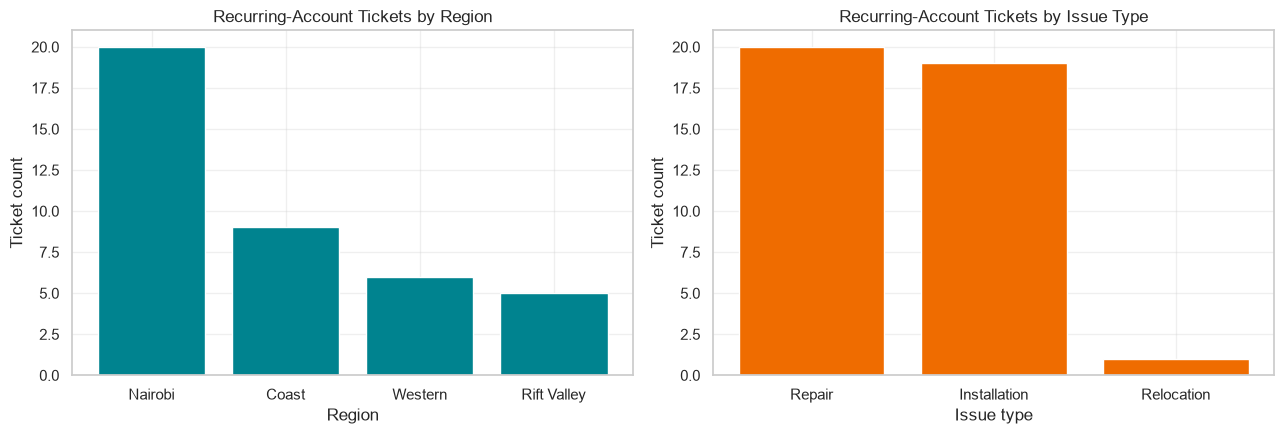

In [33]:
# Bonus: Cross-tab: do recurring accounts cluster by region or issue_type?
recurring_account_numbers = recurring_accounts["account_number"]
recurring_tickets = tickets[tickets["account_number"].isin(recurring_account_numbers)]

print(f"Tickets from recurring accounts: {len(recurring_tickets)}\n")

# --- By region ---
region_breakdown = (
    recurring_tickets["region"]
    .value_counts()
    .reset_index()
    .rename(columns={"count": "ticket_count"})
)
region_breakdown["pct"] = (region_breakdown["ticket_count"] / len(recurring_tickets) * 100).round(1)
print("Recurring-account tickets by region:")
print(region_breakdown.to_string(index=False))

# --- By issue_type ---
issue_breakdown = (
    recurring_tickets["issue_type"]
    .value_counts()
    .reset_index()
    .rename(columns={"count": "ticket_count"})
)
issue_breakdown["pct"] = (issue_breakdown["ticket_count"] / len(recurring_tickets) * 100).round(1)
print("\nRecurring-account tickets by issue type:")
print(issue_breakdown.to_string(index=False))

# --- Plot: side-by-side comparison ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(region_breakdown["region"], region_breakdown["ticket_count"], color="#00838F")
axes[0].set_title("Recurring-Account Tickets by Region")
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Ticket count")

axes[1].bar(issue_breakdown["issue_type"], issue_breakdown["ticket_count"], color="#EF6C00")
axes[1].set_title("Recurring-Account Tickets by Issue Type")
axes[1].set_xlabel("Issue type")
axes[1].set_ylabel("Ticket count")

plt.tight_layout()
plt.show()

>**Recurring-account cross-tab results:** Of the 40 tickets tied to recurring accounts, the regional split (Nairobi 50%, Coast 22.5%, Western 15%, Rift Valley 12.5%) closely mirrors the overall revenue distribution across regions found in F1 (Nairobi also led on total volume and revenue there) — so recurrence doesn't appear to be disproportionately concentrated in any one region relative to its overall ticket share; it largely just tracks where the bulk of business already is.

>**The issue-type split is the more striking finding:** Repair (50%) and Installation (47.5%) account for nearly all recurring-account tickets, while Relocation makes up just 2.5% — effectively negligible. This suggests recurrence is overwhelmingly tied to Repair and Installation work specifically, not evenly spread across issue types. That's a meaningful operational signal: it points toward either incomplete first-time fixes (a repair that doesn't fully resolve the underlying problem, prompting a follow-up ticket) or installation quality issues (an install that later needs a repair/adjustment call) as the likely drivers of repeat contact — while relocations, by contrast, appear to be largely "one-and-done" once completed. This is a more actionable lead than the region split, and worth prioritizing if investigating root causes: reviewing repair/installation completion quality is likely to have more impact on reducing recurrence than any regional intervention.

<a id="bonus-risk-matrix"></a>
#### Engineer Risk Matrix

**Synthesizing ticket volume, SLA compliance, and net contribution into a single view — where do the strongest performers and highest-risk engineers sit relative to each other?**

       engineer  ticket_count  sla_compliance_pct  net_contribution
   Brian Otieno            34              100.00         103429.56
Esther Nyambura            31               39.13          73429.56
  Faith Wanjiru            30              100.00          78429.56
   Linda Chebet            29               81.82          68429.56
    Kevin Mutua            25               84.21          53429.56
  Grace Achieng            23               85.71          63429.56
  Dennis Kiptoo            18               23.08          23429.56
  Samuel Wafula            18               61.54          23429.56
  Sarah Njoroge            17               69.23          23429.56
   Peter Omondi            13               58.33          25357.97
 Josephine Auma             6               50.00          -7713.63
  Michael Kamau             2              100.00          -8856.81


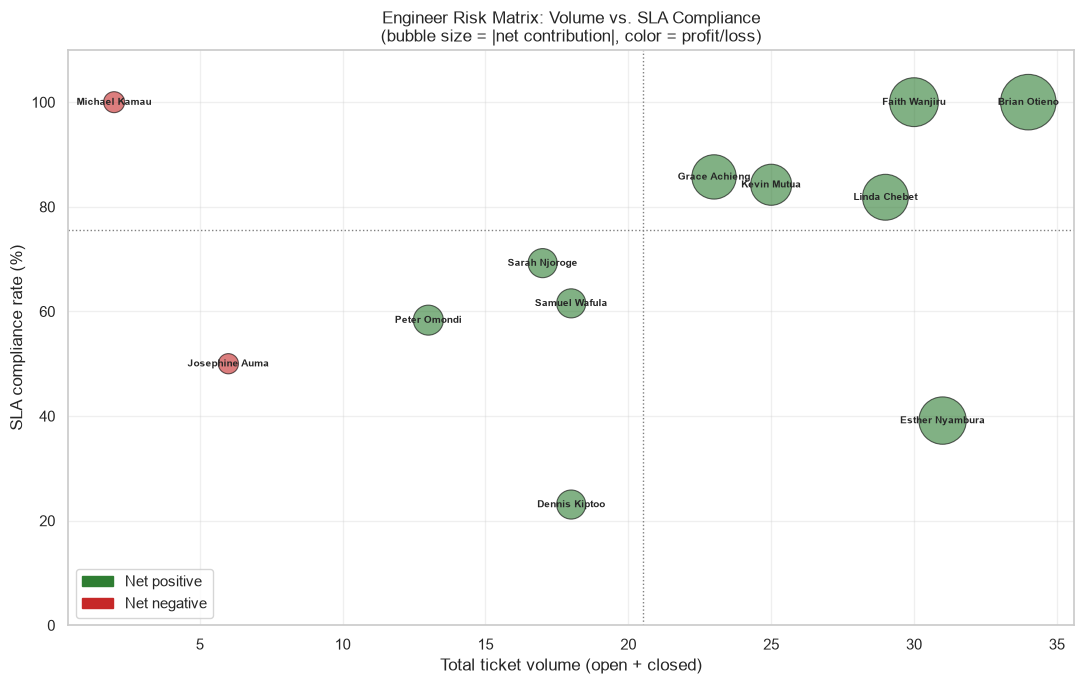

In [34]:
# Bonus: Engineer risk matrix — volume vs. SLA compliance vs. net contribution
risk_matrix = engineer_volume.merge(engineer_sla, on="engineer", how="left").merge(
    engineer_perf[["engineer", "net_contribution"]], on="engineer", how="left"
)

print(risk_matrix.to_string(index=False))

# --- Plot ---
fig, ax = plt.subplots(figsize=(11, 7))

sizes = risk_matrix["net_contribution"].abs() / risk_matrix["net_contribution"].abs().max() * 1500 + 100
colors = risk_matrix["net_contribution"].apply(lambda x: "#2E7D32" if x >= 0 else "#C62828")

scatter = ax.scatter(
    risk_matrix["ticket_count"],
    risk_matrix["sla_compliance_pct"],
    s=sizes, c=colors, alpha=0.6, edgecolor="black", linewidth=0.8
)

for _, row in risk_matrix.iterrows():
    ax.annotate(
        row["engineer"],
        xy=(row["ticket_count"], row["sla_compliance_pct"]),
        xytext=(0, 0), textcoords="offset points",
        ha="center", va="center", fontsize=7.5, fontweight="bold"
    )

median_volume = risk_matrix["ticket_count"].median()
median_sla = risk_matrix["sla_compliance_pct"].median()
ax.axvline(median_volume, color="gray", linestyle=":", linewidth=1)
ax.axhline(median_sla, color="gray", linestyle=":", linewidth=1)

ax.set_title("Engineer Risk Matrix: Volume vs. SLA Compliance\n(bubble size = |net contribution|, color = profit/loss)")
ax.set_xlabel("Total ticket volume (open + closed)")
ax.set_ylabel("SLA compliance rate (%)")
ax.set_ylim(0, 110)

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color="#2E7D32", label="Net positive"),
    Patch(color="#C62828", label="Net negative"),
], loc="lower left")

plt.tight_layout()
plt.show()

>**Risk Matrix:** This view synthesizes findings from D2–D4 onto a single chart. Engineers in the bottom-right quadrant (high volume, low SLA compliance) represent the highest operational risk regardless of their profitability, since they're handling a large share of total workload at below-average quality — this is where Esther Nyambura's risk becomes visually explicit. Conversely, engineers in the top-right quadrant (high volume, high SLA compliance) represent the strongest performers on the team — Brian Otieno and Faith Wanjiru stand out here, each combining the highest ticket volumes with 100% SLA compliance and among the largest net contributions, making them the clearest candidates for recognition.

<a id="bonus-heatmap"></a>
#### Engineer x Region Heatmap Distribution

**Which engineers work which regions, and does Rift Valley's weaker performance trace back to a specific engineer or region-wide understaffing?**

region           Coast  Nairobi  Rift Valley  Western
engineer                                             
Brian Otieno         7       20            3        4
Dennis Kiptoo        4        9            4        1
Esther Nyambura      8       12            8        3
Faith Wanjiru       10       16            4        0
Grace Achieng        8        7            6        2
Josephine Auma       0        3            2        1
Kevin Mutua          5       15            2        3
Linda Chebet         8       17            0        4
Michael Kamau        0        2            0        0
Peter Omondi         6        4            1        2
Samuel Wafula        5        8            4        1
Sarah Njoroge        6        4            3        4


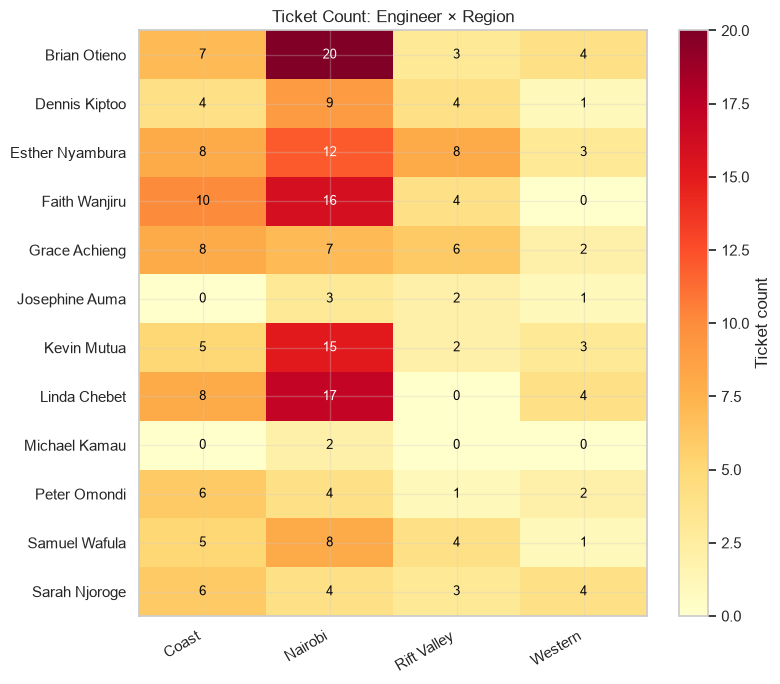


Number of distinct regions worked, per engineer:
engineer
Brian Otieno       4
Dennis Kiptoo      4
Esther Nyambura    4
Grace Achieng      4
Sarah Njoroge      4
Kevin Mutua        4
Samuel Wafula      4
Peter Omondi       4
Faith Wanjiru      3
Josephine Auma     3
Linda Chebet       3
Michael Kamau      1


In [35]:
# Bonus: Engineer x Region cross-tab — which engineers work which regions?

engineer_region = pd.crosstab(tickets["engineer"], tickets["region"])
print(engineer_region)

# --- Heatmap visualization ---
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(engineer_region.values, cmap="YlOrRd", aspect="auto")

ax.set_xticks(range(len(engineer_region.columns)))
ax.set_xticklabels(engineer_region.columns, rotation=30, ha="right")
ax.set_yticks(range(len(engineer_region.index)))
ax.set_yticklabels(engineer_region.index)

# Annotate each cell with its count
for i in range(engineer_region.shape[0]):
    for j in range(engineer_region.shape[1]):
        val = engineer_region.values[i, j]
        ax.text(j, i, val, ha="center", va="center",
                color="white" if val > engineer_region.values.max()/2 else "black", fontsize=9)

ax.set_title("Ticket Count: Engineer × Region")
fig.colorbar(im, ax=ax, label="Ticket count")
plt.tight_layout()
plt.show()

# --- How many regions does each engineer cover? ---
regions_per_engineer = (engineer_region > 0).sum(axis=1).sort_values(ascending=False)
print("\nNumber of distinct regions worked, per engineer:")
print(regions_per_engineer.to_string())

>**Engineer dispatch pattern:** Engineers are not assigned to a single home region; most work tickets across 3–4 different regions. Dennis Kiptoo — flagged in C4 for his 3 outlier long-resolution tickets — indeed works across all four regions (Coast, Nairobi, Rift Valley, Western), lending support to the travel/dispatch hypothesis raised earlier rather than ruling it out. Meanwhile, Rift Valley's low performance (from F1) can't be explained by a single under-resourced engineer — 8 of the 12 engineers have handled at least one Rift Valley ticket, meaning the region's weak SLA compliance and high MTTR reflect a broader team-wide pattern rather than one engineer's shortfall, which shifts the F2 recommendation slightly: rather than "assign Rift Valley to a better engineer," the fix is more likely structural (routing, distance, or regional infrastructure) than a personnel swap.